<a href="https://colab.research.google.com/github/shumailkhan845/CV-mid-lab/blob/main/FA23_BAI_050_Shumail_labmid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install medmnist opencv-python-headless scikit-image scikit-learn matplotlib seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]


In [2]:

import numpy as np
import matplotlib.pyplot as plt
import medmnist

from medmnist import BloodMNIST
from collections import Counter
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.svm import LinearSVC
from skimage.feature import hog
import cv2

# Personal settings
SEED = 50
HOG_CELL_SIZE = 8
SIFT_GRID_SIZE = 4

np.random.seed(SEED)

print("Random seed:", SEED)
print("HOG cell size:", HOG_CELL_SIZE, "x", HOG_CELL_SIZE)
print("SIFT grid:", SIFT_GRID_SIZE, "x", SIFT_GRID_SIZE)
print("SIFT feature length:", SIFT_GRID_SIZE**2 * 128)


Random seed: 50
HOG cell size: 8 x 8
SIFT grid: 4 x 4
SIFT feature length: 2048


In [3]:

train_dataset = BloodMNIST(split="train", size=64, download=True)
val_dataset = BloodMNIST(split="val", size=64, download=True)
test_dataset = BloodMNIST(split="test", size=64, download=True)

print("Original dataset sizes:")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))


100%|██████████| 156M/156M [02:59<00:00, 869kB/s] 


Original dataset sizes:
Train: 11959
Validation: 1712
Test: 3421


In [4]:

print("Available class labels:", train_dataset.labels.shape)
print("Unique training labels:", np.unique(train_dataset.labels))
print("First 10 labels:", train_dataset.labels[:10].ravel())


Available class labels: (11959, 1)
Unique training labels: [0 1 2 3 4 5 6 7]
First 10 labels: [7 3 6 6 7 6 2 2 7 2]


In [5]:

# Required classes
SELECTED_CLASSES = [1, 5, 6, 7]

CLASS_NAMES = {
    1: "Eosinophil",
    5: "Monocyte",
    6: "Neutrophil",
    7: "Platelet"
}

def prepare_split(dataset, samples_per_class, seed):
    images = dataset.imgs
    labels = dataset.labels.ravel()

    selected_images = []
    selected_labels = []

    rng = np.random.default_rng(seed)

    for class_id in SELECTED_CLASSES:
        # Find all indices belonging to this class
        class_indices = np.where(labels == class_id)[0]

        # Randomly choose the required number of images
        chosen_indices = rng.choice(
            class_indices,
            size=samples_per_class,
            replace=False
        )

        selected_images.extend(images[chosen_indices])
        selected_labels.extend(labels[chosen_indices])

    selected_images = np.array(selected_images)
    selected_labels = np.array(selected_labels)

    # Shuffle the selected samples
    order = rng.permutation(len(selected_labels))

    return selected_images[order], selected_labels[order]


X_train_raw, y_train = prepare_split(train_dataset, 100, SEED)
X_val_raw, y_val = prepare_split(val_dataset, 30, SEED + 1)
X_test_raw, y_test = prepare_split(test_dataset, 30, SEED + 2)

print("Training shape:", X_train_raw.shape, y_train.shape)
print("Validation shape:", X_val_raw.shape, y_val.shape)
print("Testing shape:", X_test_raw.shape, y_test.shape)

for name, labels in [
    ("Train", y_train),
    ("Validation", y_val),
    ("Test", y_test)
]:
    print(f"\n{name} class counts:")
    for class_id in SELECTED_CLASSES:
        print(f"{CLASS_NAMES[class_id]} ({class_id}):",
              np.sum(labels == class_id))


Training shape: (400, 64, 64, 3) (400,)
Validation shape: (120, 64, 64, 3) (120,)
Testing shape: (120, 64, 64, 3) (120,)

Train class counts:
Eosinophil (1): 100
Monocyte (5): 100
Neutrophil (6): 100
Platelet (7): 100

Validation class counts:
Eosinophil (1): 30
Monocyte (5): 30
Neutrophil (6): 30
Platelet (7): 30

Test class counts:
Eosinophil (1): 30
Monocyte (5): 30
Neutrophil (6): 30
Platelet (7): 30


In [6]:

def preprocess_images(images):
    processed = []

    for image in images:
        # Convert RGB to grayscale
        gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

        # Resize to 128 x 128
        resized = cv2.resize(
            gray, (128, 128),
            interpolation=cv2.INTER_LINEAR
        )

        # Scale pixel values to 0-1
        resized = resized.astype(np.float32) / 255.0
        processed.append(resized)

    return np.array(processed)


X_train = preprocess_images(X_train_raw)
X_val = preprocess_images(X_val_raw)
X_test = preprocess_images(X_test_raw)

print("Processed training:", X_train.shape)
print("Processed validation:", X_val.shape)
print("Processed testing:", X_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max())


Processed training: (400, 128, 128)
Processed validation: (120, 128, 128)
Processed testing: (120, 128, 128)
Pixel range: 0.13725491 to 0.93333334


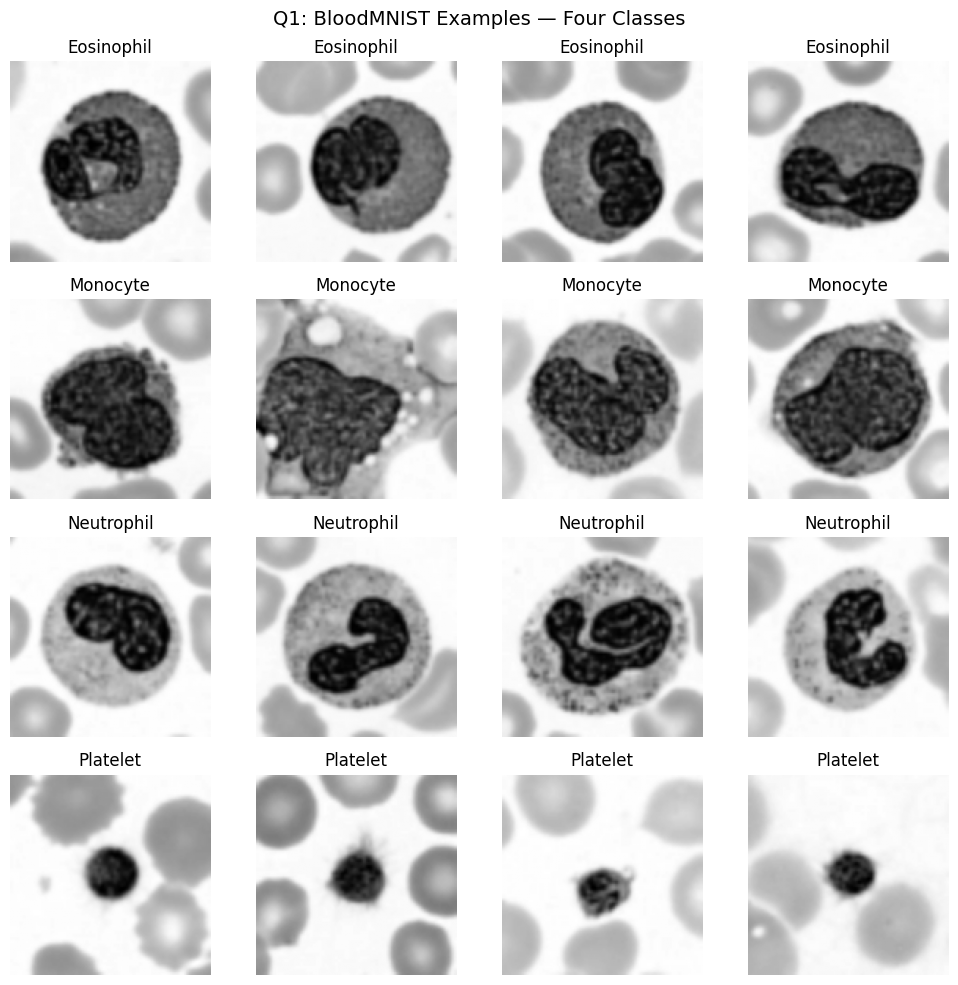

In [7]:

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for row, class_id in enumerate(SELECTED_CLASSES):
    class_indices = np.where(y_train == class_id)[0][:4]

    for col, idx in enumerate(class_indices):
        axes[row, col].imshow(X_train[idx], cmap="gray")
        axes[row, col].set_title(CLASS_NAMES[class_id])
        axes[row, col].axis("off")

plt.suptitle("Q1: BloodMNIST Examples — Four Classes", fontsize=14)
plt.tight_layout()
plt.show()


In [8]:

from skimage.feature import hog

def extract_hog_features(images):
    features = []

    for image in images:
        feature = hog(
            image,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )
        features.append(feature)

    return np.array(features)


X_train_hog = extract_hog_features(X_train)
X_val_hog = extract_hog_features(X_val)

print("HOG training features:", X_train_hog.shape)
print("HOG validation features:", X_val_hog.shape)
print("HOG feature length:", X_train_hog.shape[1])
print("Manual calculation:", 15 * 15 * 2 * 2 * 9)


HOG training features: (400, 8100)
HOG validation features: (120, 8100)
HOG feature length: 8100
Manual calculation: 8100


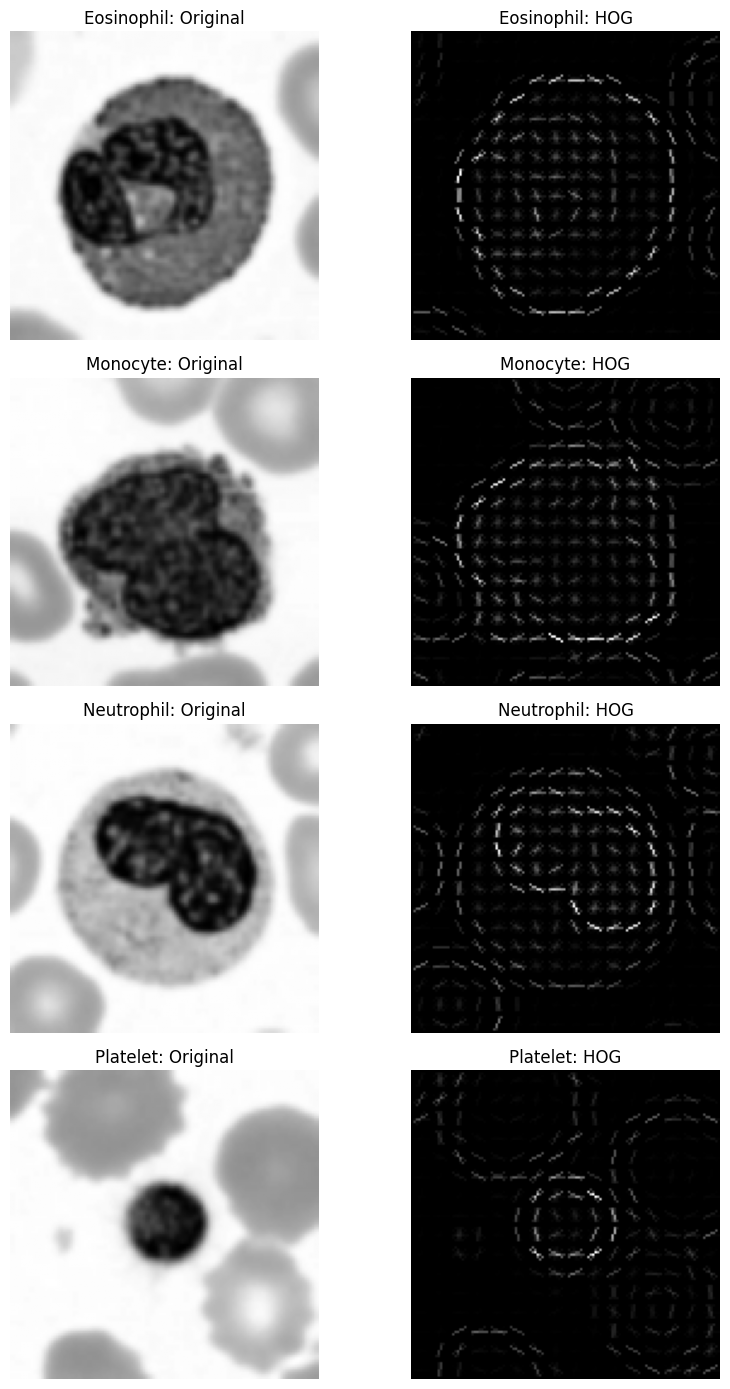

In [9]:

fig, axes = plt.subplots(4, 2, figsize=(9, 14))

for row, class_id in enumerate(SELECTED_CLASSES):
    idx = np.where(y_train == class_id)[0][0]

    _, hog_image = hog(
        X_train[idx],
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys",
        visualize=True,
        feature_vector=True
    )

    axes[row, 0].imshow(X_train[idx], cmap="gray")
    axes[row, 0].set_title(f"{CLASS_NAMES[class_id]}: Original")

    axes[row, 1].imshow(hog_image, cmap="gray")
    axes[row, 1].set_title(f"{CLASS_NAMES[class_id]}: HOG")

    axes[row, 0].axis("off")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()


In [10]:

from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

C_VALUES = [0.1, 1, 10]

best_hog_model = None
best_hog_C = None
best_hog_accuracy = -1

for C in C_VALUES:
    model = LinearSVC(C=C, random_state=SEED, max_iter=10000)
    model.fit(X_train_hog, y_train)

    val_predictions = model.predict(X_val_hog)
    val_accuracy = accuracy_score(y_val, val_predictions)
    val_macro_f1 = f1_score(
        y_val, val_predictions,
        labels=SELECTED_CLASSES,
        average="macro",
        zero_division=0
    )

    print(f"\nC = {C}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print(f"Validation macro-F1: {val_macro_f1:.4f}")

    if val_accuracy > best_hog_accuracy:
        best_hog_accuracy = val_accuracy
        best_hog_C = C
        best_hog_model = model

best_hog_predictions = best_hog_model.predict(X_val_hog)

print("\nSelected HOG C:", best_hog_C)
print("Best validation accuracy:", accuracy_score(y_val, best_hog_predictions))
print("Best validation macro-F1:",
      f1_score(y_val, best_hog_predictions,
               labels=SELECTED_CLASSES, average="macro", zero_division=0))
print("Validation confusion matrix:")
print(confusion_matrix(y_val, best_hog_predictions,
                       labels=SELECTED_CLASSES))



C = 0.1
Validation accuracy: 0.6667
Validation macro-F1: 0.6663

C = 1
Validation accuracy: 0.6750
Validation macro-F1: 0.6741

C = 10
Validation accuracy: 0.6750
Validation macro-F1: 0.6741

Selected HOG C: 1
Best validation accuracy: 0.675
Best validation macro-F1: 0.674143429925278
Validation confusion matrix:
[[16  7  7  0]
 [ 5 20  5  0]
 [ 8  5 16  1]
 [ 0  0  1 29]]


In [11]:

sift = cv2.SIFT_create()

keypoint_counts = []

for image in X_train:
    # Convert normalized grayscale image to uint8
    image_uint8 = (image * 255).astype(np.uint8)

    keypoints, descriptors = sift.detectAndCompute(
        image_uint8, None
    )

    keypoint_counts.append(len(keypoints))

keypoint_counts = np.array(keypoint_counts)

print("Average keypoints:", keypoint_counts.mean())
print("Minimum keypoints:", keypoint_counts.min())
print("Maximum keypoints:", keypoint_counts.max())
print("Images with zero keypoints:", np.sum(keypoint_counts == 0))


Average keypoints: 72.365
Minimum keypoints: 7
Maximum keypoints: 227
Images with zero keypoints: 0


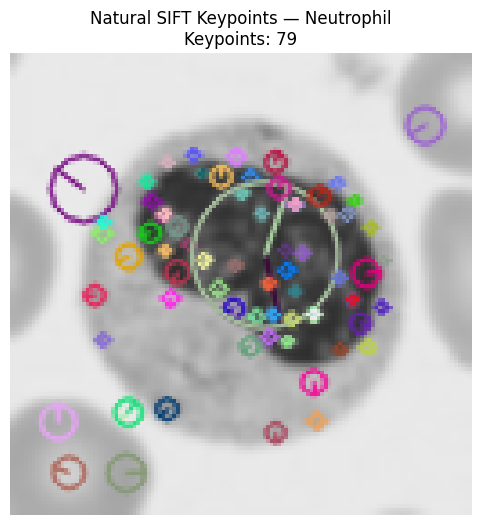

In [12]:

idx = 0

image_uint8 = (X_train[idx] * 255).astype(np.uint8)
keypoints, descriptors = sift.detectAndCompute(image_uint8, None)

image_with_keypoints = cv2.drawKeypoints(
    image_uint8,
    keypoints,
    None,
    flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)

plt.figure(figsize=(6, 6))
plt.imshow(image_with_keypoints, cmap="gray")
plt.title(
    f"Natural SIFT Keypoints — {CLASS_NAMES[int(y_train[idx])]}\n"
    f"Keypoints: {len(keypoints)}"
)
plt.axis("off")
plt.show()


In [13]:

GRID_SIZE = 4
KEYPOINT_SIZE = 32

# Regular grid coordinates, safely inside the 128 x 128 image
grid_coordinates = np.linspace(16, 112, GRID_SIZE)

def extract_grid_sift(image):
    image_uint8 = np.clip(image * 255, 0, 255).astype(np.uint8)

    keypoints = [
        cv2.KeyPoint(
            float(x), float(y), float(KEYPOINT_SIZE)
        )
        for y in grid_coordinates
        for x in grid_coordinates
    ]

    keypoints, descriptors = sift.compute(image_uint8, keypoints)

    if descriptors is None or len(keypoints) != GRID_SIZE**2:
        raise ValueError(
            f"Expected 16 descriptors, got "
            f"{0 if descriptors is None else len(descriptors)}"
        )

    return descriptors.flatten()


X_train_sift = np.array([
    extract_grid_sift(image) for image in X_train
])

X_val_sift = np.array([
    extract_grid_sift(image) for image in X_val
])

print("Grid points:", GRID_SIZE**2)
print("Descriptor length:", 128)
print("Expected feature length:", GRID_SIZE**2 * 128)
print("Training SIFT features:", X_train_sift.shape)
print("Validation SIFT features:", X_val_sift.shape)


Grid points: 16
Descriptor length: 128
Expected feature length: 2048
Training SIFT features: (400, 2048)
Validation SIFT features: (120, 2048)


In [14]:

C_VALUES = [0.1, 1, 10]

best_sift_model = None
best_sift_C = None
best_sift_accuracy = -1

for C in C_VALUES:
    model = LinearSVC(C=C, random_state=SEED, max_iter=10000)
    model.fit(X_train_sift, y_train)

    val_predictions = model.predict(X_val_sift)

    val_accuracy = accuracy_score(y_val, val_predictions)
    val_macro_f1 = f1_score(
        y_val,
        val_predictions,
        labels=SELECTED_CLASSES,
        average="macro",
        zero_division=0
    )

    print(f"\nC = {C}")
    print(f"Validation accuracy: {val_accuracy:.4f}")
    print(f"Validation macro-F1: {val_macro_f1:.4f}")

    if val_accuracy > best_sift_accuracy:
        best_sift_accuracy = val_accuracy
        best_sift_C = C
        best_sift_model = model

best_sift_predictions = best_sift_model.predict(X_val_sift)

print("\nSelected SIFT C:", best_sift_C)
print("Best validation accuracy:",
      accuracy_score(y_val, best_sift_predictions))
print("Best validation macro-F1:",
      f1_score(
          y_val,
          best_sift_predictions,
          labels=SELECTED_CLASSES,
          average="macro",
          zero_division=0
      ))

print("Validation confusion matrix:")
print(confusion_matrix(
    y_val,
    best_sift_predictions,
    labels=SELECTED_CLASSES
))


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



C = 0.1
Validation accuracy: 0.8083
Validation macro-F1: 0.8065


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(



C = 1
Validation accuracy: 0.8083
Validation macro-F1: 0.8065

C = 10
Validation accuracy: 0.8083
Validation macro-F1: 0.8065

Selected SIFT C: 0.1
Best validation accuracy: 0.8083333333333333
Best validation macro-F1: 0.8064835064698378
Validation confusion matrix:
[[19  4  7  0]
 [ 5 25  0  0]
 [ 5  0 23  2]
 [ 0  0  0 30]]


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [15]:

def rotate_image(image, angle=20):
    height, width = image.shape
    center = (width / 2, height / 2)

    matrix = cv2.getRotationMatrix2D(center, angle, 1.0)

    rotated = cv2.warpAffine(
        image,
        matrix,
        (width, height),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_REFLECT
    )

    return rotated.astype(np.float32)


def add_gaussian_noise(image, sigma=0.05, seed=SEED):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0, sigma, image.shape)

    noisy = image + noise
    return np.clip(noisy, 0.0, 1.0).astype(np.float32)


X_test_rotated = np.array([
    rotate_image(image, 20) for image in X_test
])

X_test_noisy = np.array([
    add_gaussian_noise(image, sigma=0.05, seed=SEED + i)
    for i, image in enumerate(X_test)
])

print("Clean test shape:", X_test.shape)
print("Rotated test shape:", X_test_rotated.shape)
print("Noisy test shape:", X_test_noisy.shape)
print("Noisy pixel range:",
      X_test_noisy.min(), "to", X_test_noisy.max())


Clean test shape: (120, 128, 128)
Rotated test shape: (120, 128, 128)
Noisy test shape: (120, 128, 128)
Noisy pixel range: 0.009287025 to 1.0


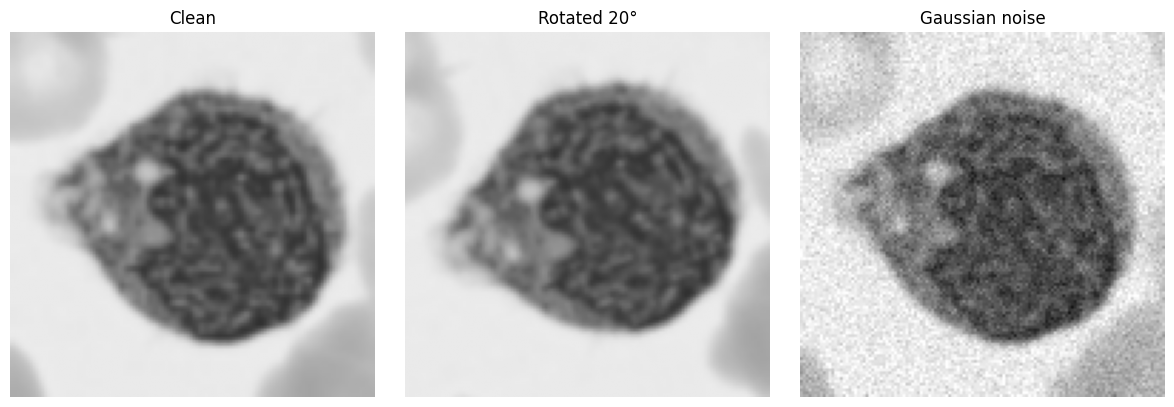

In [16]:

idx = 0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].imshow(X_test[idx], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Clean")

axes[1].imshow(X_test_rotated[idx], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("Rotated 20°")

axes[2].imshow(X_test_noisy[idx], cmap="gray", vmin=0, vmax=1)
axes[2].set_title("Gaussian noise")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [17]:

# HOG features
X_test_hog_clean = extract_hog_features(X_test)
X_test_hog_rotated = extract_hog_features(X_test_rotated)
X_test_hog_noisy = extract_hog_features(X_test_noisy)

# Fixed-grid SIFT features
X_test_sift_clean = np.array([
    extract_grid_sift(image) for image in X_test
])

X_test_sift_rotated = np.array([
    extract_grid_sift(image) for image in X_test_rotated
])

X_test_sift_noisy = np.array([
    extract_grid_sift(image) for image in X_test_noisy
])

print("HOG feature shapes:")
print(X_test_hog_clean.shape)
print(X_test_hog_rotated.shape)
print(X_test_hog_noisy.shape)

print("\nSIFT feature shapes:")
print(X_test_sift_clean.shape)
print(X_test_sift_rotated.shape)
print(X_test_sift_noisy.shape)


HOG feature shapes:
(120, 8100)
(120, 8100)
(120, 8100)

SIFT feature shapes:
(120, 2048)
(120, 2048)
(120, 2048)


In [18]:

test_features = {
    "HOG": {
        "Clean": X_test_hog_clean,
        "Rotated": X_test_hog_rotated,
        "Noisy": X_test_hog_noisy
    },
    "SIFT": {
        "Clean": X_test_sift_clean,
        "Rotated": X_test_sift_rotated,
        "Noisy": X_test_sift_noisy
    }
}

frozen_models = {
    "HOG": best_hog_model,
    "SIFT": best_sift_model
}

robustness_results = {}

for model_name, model in frozen_models.items():
    robustness_results[model_name] = {}

    for condition, features in test_features[model_name].items():
        predictions = model.predict(features)
        accuracy = accuracy_score(y_test, predictions)

        robustness_results[model_name][condition] = accuracy

        print(
            f"{model_name} | {condition}: "
            f"{accuracy:.4f} ({accuracy * 100:.2f}%)"
        )


print("\nFinal Q4 table")
print(f"{'Model':<12} {'Clean':>10} {'Rotated':>10} {'Noisy':>10}")

for model_name, values in robustness_results.items():
    print(
        f"{model_name:<12}"
        f"{values['Clean'] * 100:>9.2f}%"
        f"{values['Rotated'] * 100:>9.2f}%"
        f"{values['Noisy'] * 100:>9.2f}%"
    )


HOG | Clean: 0.6917 (69.17%)
HOG | Rotated: 0.5833 (58.33%)
HOG | Noisy: 0.5167 (51.67%)
SIFT | Clean: 0.7500 (75.00%)
SIFT | Rotated: 0.7417 (74.17%)
SIFT | Noisy: 0.7583 (75.83%)

Final Q4 table
Model             Clean    Rotated      Noisy
HOG             69.17%    58.33%    51.67%
SIFT            75.00%    74.17%    75.83%


In [19]:

for model_name, values in robustness_results.items():
    rotation_loss = (
        values["Clean"] - values["Rotated"]
    ) * 100

    noise_loss = (
        values["Clean"] - values["Noisy"]
    ) * 100

    print(f"\n{model_name}")
    print(f"Rotation accuracy loss: {rotation_loss:.2f} percentage points")
    print(f"Noise accuracy loss: {noise_loss:.2f} percentage points")



HOG
Rotation accuracy loss: 10.83 percentage points
Noise accuracy loss: 17.50 percentage points

SIFT
Rotation accuracy loss: 0.83 percentage points
Noise accuracy loss: -0.83 percentage points
